# Canal 2: the two paths to the predicted mean

Produces the supplementary figure `fig:canal2-mean-confound`.

It serves one precise sentence of the paper: *the uncertainty follows the predicted mean in the same way under both error definitions, while the error follows it in opposite directions*. That is what makes the uncontrolled value change sign, and it is the only justification for the partial correlation.

**Nothing new is computed.** The canal 2 script already writes the three correlations that enter the partial, per group and per case, in `pair_partial.parquet` and `spot_partial.parquet`:

| column | what it is |
|---|---|
| `r_um_{case}` | Spearman(uncertainty, predicted mean) **within** the group |
| `r_Dm_{case}` | Spearman(error, predicted mean) **within** the group |
| `r_uD_{case}` | the naive value |
| `r_partial_{case}` | the controlled value |

So the only thing plotted is the per-group distribution of `r_um` and of `r_Dm`, under both error definitions, on the same `y > 0` population.

**Watch the marker convention.** Everywhere else in the section, hollow and filled mean uncontrolled and controlled. That opposition has no meaning here, so **every marker is filled** and it is the **shape** that carries the quantity. The legend says so.

## 0. Config and loading

In [1]:
import sys
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.append(str(PROJ))

# =============================== SETTINGS ====================================
RUN_ID      = "pr_classic3"
RESULTS     = PROJ / "results"
DATASETS    = ["10x_TuPro", "TLS", "LUNG_CANCER"]
RADIUS      = "r75"
CANAL2      = "canal2_uncertainty"
LAMBDA_KEEP = 0.0
MODELS      = ["homoscedastic", "heteroscedastic", "spot_homoscedastic",
               "poisson_cp", "negativebinomial_hetero_noanchor_cp"]
FIGDIR      = PROJ / "results" / "_analysis" / "figures"
# =============================================================================

N_PLUS_MIN = 60
CONVENTION = "v3_native_scale"
AXES  = ["gene", "spot"]
# The TWO error definitions, on the SAME y > 0 population. That is what isolates the
# definition: on lin_all the population changes too and the comparison says nothing.
CASES = ["lin_pos", "log_pos"]

MODEL_COLORS = {
    "homoscedastic":                        "#1f77b4",
    "heteroscedastic":                      "#ff7f0e",
    "spot_homoscedastic":                   "#2ca02c",
    "poisson_cp":                           "#d62728",
    "negativebinomial_hetero_noanchor_cp":  "#9467bd",
}
MODEL_LABELS = {
    "homoscedastic":                        "Gaussian gene-homoscedastic",
    "heteroscedastic":                      "Gaussian heteroscedastic",
    "spot_homoscedastic":                   "Gaussian spot-homoscedastic",
    "poisson_cp":                           "Poisson",
    "negativebinomial_hetero_noanchor_cp":  "Negative binomial",
}
DATASET_LABELS = {"10x_TuPro": "Tumor Profiler", "TLS": "Kidney/Lung with TLS",
                  "LUNG_CANCER": "NSCLC"}

# The three quantities drawn. The SHAPE carries the quantity, every marker is filled.
#   (key, column, case, marker, label)
QUANTS = [
    ("um",  "r_um", "lin_pos", "o", "uncertainty vs predicted mean"),
    ("Dm1", "r_Dm", "lin_pos", "s", "absolute error vs predicted mean"),
    ("Dm2", "r_Dm", "log_pos", "D", "log-ratio error vs predicted mean"),
]

def canal_dir(ds, model):
    base = RESULTS / ds / RUN_ID / f"_{ds}_hvg_top3000" / RADIUS / model
    if not base.is_dir():
        return None
    for leaf in [base] + sorted(base.glob("lambda_*")):
        if leaf.name.startswith("lambda_"):
            if LAMBDA_KEEP is None or not np.isclose(float(leaf.name[len("lambda_"):]), LAMBDA_KEEP):
                continue
        d = leaf / CANAL2
        if (d / "summary.json").is_file():
            s = json.loads((d / "summary.json").read_text())
            if s.get("not_applicable") or s.get("canal2_convention") != CONVENTION:
                return None
            return d
    return None

FRAMES, missing = {}, []
for ds in DATASETS:
    for m in MODELS:
        d = canal_dir(ds, m)
        if d is None:
            missing.append((ds, m))
            continue
        for axis, fname in (("gene", "pair_partial.parquet"), ("spot", "spot_partial.parquet")):
            f = d / fname
            if f.is_file():
                FRAMES[(ds, m, axis)] = pd.read_parquet(f)

print(f"canal2 = {CANAL2!r}   run = {RUN_ID}")
print(f"  {len(FRAMES)} parquet(s) read out of {len(DATASETS) * len(MODELS) * len(AXES)} expected")
if missing:
    print(f"  (!) no conforming precomputation: {missing}")

# CHECK: r_um does NOT depend on the error definition, only on the population. Since lin_pos
# and log_pos share the y > 0 population, the two columns must be IDENTICAL. If this check
# fails the figure means nothing: it rests entirely on that equality.
bad = 0
for k, fr in FRAMES.items():
    a, b = fr.get("r_um_lin_pos"), fr.get("r_um_log_pos")
    if a is None or b is None:
        continue
    if not np.allclose(a.to_numpy(), b.to_numpy(), equal_nan=True, atol=1e-9):
        bad += 1
        print(f"  (!) r_um differs between lin_pos and log_pos: {k}")
print(f"  check r_um identical under both definitions: {len(FRAMES) - bad}/{len(FRAMES)} OK")

canal2 = 'canal2_uncertainty'   run = pr_classic3
  30 parquet(s) read out of 30 expected
  check r_um identical under both definitions: 30/30 OK


## 1. The figure

One head per group of three markers. Point = **median over groups**, bar = **interquartile range**, because these are per-group quantities and a mean alone would hide their spread.

What to read, in this order:

1. the **circle** is on the same side for every head: the predicted uncertainty follows the predicted mean;
2. the **square** and the **diamond** sit on either side of zero: the absolute error rises with the mean, the relative error falls;
3. the circle does not move from one definition to the other, and that is checked numerically in the previous cell.

Hence the sign reversal of the uncontrolled value, and hence the need for the partial correlation.

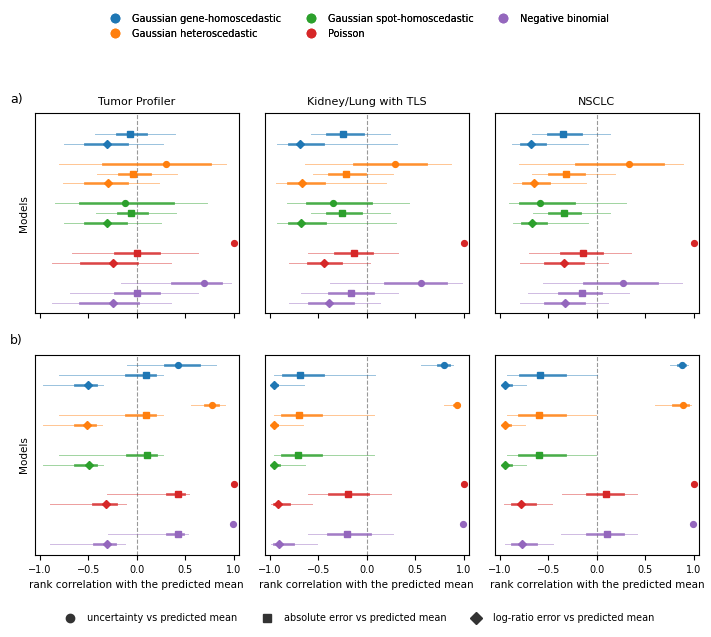

## FIGURE  fig_canal2_mean_confound_pr_classic3_v3.pdf
## TITLE   The two paths to the predicted mean, within a group
## CAPTION Every quantity is a Spearman correlation computed INSIDE a group and then summarized
## CAPTION over groups: point = median, thick bar = interquartile range, thin bar = 5th to
## CAPTION 95th percentile. Colors are the predictive
## CAPTION heads; the SHAPE carries the quantity, and all markers are filled, because the
## CAPTION hollow-versus-filled convention used elsewhere in the section has no meaning here.
## CAPTION o = uncertainty vs predicted mean.
## CAPTION s = absolute error vs predicted mean.
## CAPTION D = log-ratio error vs predicted mean.
## CAPTION a) grouping: one group per gene and slide, across the spots of that gene.
## CAPTION b) grouping: one group per slide and spot, across the genes of that spot.
## CAPTION Both error definitions are read on the same entries, those where the gene is
## CAPTION detected, so the only thing that differs be

In [2]:
from matplotlib.lines import Line2D

FIGDIR.mkdir(parents=True, exist_ok=True)

def fig_show(fig, stem, title, caption):
    fig.savefig(f"{stem}.pdf", bbox_inches="tight")
    fig.savefig(f"{stem}.png", dpi=300, bbox_inches="tight")
    plt.show()
    print(f"## FIGURE  {stem.name}.pdf")
    print(f"## TITLE   {title}")
    for line in caption:
        print(f"## CAPTION {line}")

AXIS_GROUPING = {
    "gene": "one group per gene and slide, across the spots of that gene",
    "spot": "one group per slide and spot, across the genes of that spot",
}

def stats_over_groups(ds, m, axis, col, case):
    """Median and quartiles of the column, over the groups that pass the floor."""
    fr = FRAMES.get((ds, m, axis))
    c = f"{col}_{case}"
    if fr is None or c not in fr.columns or "n_plus_pos" not in fr.columns:
        return None
    v = fr.loc[fr["n_plus_pos"] >= N_PLUS_MIN, c].dropna()
    if v.empty:
        return None
    return dict(med=float(v.median()), q25=float(v.quantile(0.25)),
                q75=float(v.quantile(0.75)), p05=float(v.quantile(0.05)),
                p95=float(v.quantile(0.95)), n=int(len(v)))

GAP, STEP = 0.75, 3.0
rows = []
fig, axes = plt.subplots(len(AXES), len(DATASETS),
                         figsize=(2.4 * len(DATASETS), 3.0 * len(AXES)), sharex=True)
axes = np.atleast_2d(axes)
for i, axis in enumerate(AXES):
    for j, ds in enumerate(DATASETS):
        ax = axes[i, j]
        for k, m in enumerate(MODELS):
            c = MODEL_COLORS.get(m, "0.4")
            for t, (key, col, case, mk, _lab) in enumerate(QUANTS):
                st = stats_over_groups(ds, m, axis, col, case)
                if st is None:
                    continue
                y = k * STEP + t * GAP
                # Two bars rather than a violin: the thin line carries the 5th to 95th
                # percentiles, so the tails, and the thick line the interquartile range. A violin
                # or a box would hide the marker, and here the marker SHAPE identifies the quantity.
                ax.plot([st["p05"], st["p95"]], [y, y], color=c, lw=0.7, alpha=0.45, zorder=2)
                ax.plot([st["q25"], st["q75"]], [y, y], color=c, lw=2.0, alpha=0.75, zorder=3)
                ax.plot([st["med"]], [y], mk, ms=4.2, color=c, zorder=4)
                rows.append(dict(axis=axis, dataset=ds, model=m, quantity=key, **st))
        ax.axvline(0.0, color="0.6", lw=0.8, ls="--", zorder=1)
        ax.set_xlim(-1.05, 1.05)
        ax.set_yticks([])
        ax.set_ylim(-0.8, (len(MODELS) - 1) * STEP + (len(QUANTS) - 1) * GAP + 0.8)
        ax.invert_yaxis()
        ax.tick_params(axis="x", labelsize=7)
        if j == 0:
            ax.set_ylabel("Models", fontsize=7.5)
            ax.text(-0.06, 1.04, f"{'ab'[i]})", transform=ax.transAxes,
                    ha="right", va="bottom", fontsize=9)
        if i == len(AXES) - 1:
            ax.set_xlabel("rank correlation with the predicted mean", fontsize=7.5)
        if i == 0:
            ax.set_title(DATASET_LABELS.get(ds, ds), fontsize=8)

model_handles = [Line2D([], [], marker="o", ls="", color=MODEL_COLORS.get(m, "0.4"),
                        label=MODEL_LABELS.get(m, m)) for m in MODELS]
quant_handles = [Line2D([], [], marker=mk, ls="", color="#333333", label=lab)
                 for _k, _c, _cs, mk, lab in QUANTS]
fig.tight_layout(rect=(0, 0, 1, 0.88))
leg1 = fig.legend(handles=model_handles, loc="upper center", bbox_to_anchor=(0.5, 1.0),
                  ncol=3, frameon=False, fontsize=7)
fig.add_artist(leg1)
fig.legend(handles=quant_handles, loc="lower center", ncol=3, frameon=False, fontsize=7,
           bbox_to_anchor=(0.5, -0.045))

fig_show(fig, FIGDIR / f"fig_canal2_mean_confound_{RUN_ID}_v3",
         "The two paths to the predicted mean, within a group",
         ["Every quantity is a Spearman correlation computed INSIDE a group and then summarized",
          "over groups: point = median, thick bar = interquartile range, thin bar = 5th to",
          "95th percentile. Colors are the predictive",
          "heads; the SHAPE carries the quantity, and all markers are filled, because the",
          "hollow-versus-filled convention used elsewhere in the section has no meaning here.",
          *[f"{mk} = {lab}." for _k, _c, _cs, mk, lab in QUANTS],
          *[f"{'ab'[q]}) grouping: {AXIS_GROUPING[a]}." for q, a in enumerate(AXES)],
          "Both error definitions are read on the same entries, those where the gene is",
          "detected, so the only thing that differs between the square and the diamond is the",
          "definition. The circle is identical under the two, which is checked numerically and",
          "is why only one is drawn.",
          "The uncertainty follows the predicted mean the same way in every case, while the",
          "error follows it in opposite directions. The component the two share therefore",
          "reverses with the definition, which is what makes the uncontrolled correlation",
          "change sign and what the partial correlation exists to remove."])

T = pd.DataFrame(rows)
print()
print("=" * 110)
print("THE PRINTED TWIN: median [Q25, Q75] over groups")
print("=" * 110)
for axis in AXES:
    sub = T[T["axis"] == axis]
    if sub.empty:
        continue
    print()
    print(f"[{axis} axis]")
    print(f"    {'cohort':<22s} {'head':<32s} {'quant':<5s} {'median':>9s} {'Q25':>8s} {'Q75':>8s} {'n grp':>8s}")
    for _, r in sub.iterrows():
        print(f"    {DATASET_LABELS.get(r['dataset'], r['dataset']):<22s} "
              f"{MODEL_LABELS.get(r['model'], r['model']):<32s} {r['quantity']:<5s} "
              f"{r['med']:>+9.4f} {r['q25']:>+8.4f} {r['q75']:>+8.4f} {r['n']:>8d}")

print()
print("-- the reversal, tested: median(r_Dm) must change sign between the two definitions --")
ok = bad = 0
for axis in AXES:
    for ds in DATASETS:
        for m in MODELS:
            a = T[(T["axis"] == axis) & (T["dataset"] == ds) & (T["model"] == m) & (T["quantity"] == "Dm1")]
            b = T[(T["axis"] == axis) & (T["dataset"] == ds) & (T["model"] == m) & (T["quantity"] == "Dm2")]
            if a.empty or b.empty:
                continue
            va, vb = float(a["med"].iloc[0]), float(b["med"].iloc[0])
            flips = (va > 0) != (vb > 0)
            ok, bad = (ok + 1, bad) if flips else (ok, bad + 1)
            if not flips:
                print(f"  (!) no reversal  {axis:<5s} {ds:<12s} {m:<38s} "
                      f"abs {va:+.4f}  log {vb:+.4f}")
print(f"  -> {ok} cell(s) with a reversal, {bad} without.")